# 🏆 Análisis Exploratorio Avanzado (EDA): Historia y Evolución de los Mundiales de Fútbol

## 📋 1. Introducción y Objetivos del Proyecto
* **Propósito:** Realizar un análisis profundo del rendimiento histórico de los Mundiales de Fútbol (1930-2026) combinando métricas globales de partidos con resúmenes estructurales de equipos.
* **Preguntas de Negocio / Hipótesis a Resolver:**
  1. ¿Cómo ha mutado el comportamiento ofensivo real más allá del simple aumento de partidos?
  2. ¿Existen patrones ocultos en las fases del torneo que determinen la competitividad?
  3. ¿Cómo se relacionan las estadísticas históricas con el contexto actual de las selecciones?

In [21]:
import pandas as pd

df_matches = pd.read_csv('../data/WorldCupMatches-selected-columns.csv')
df_teams = pd.read_csv('../data/2026_team_summaries.csv')

print("Partidos cargados:", df_matches.shape)
print("Equipos cargados:", df_teams.shape)

Partidos cargados: (1074, 10)
Equipos cargados: (48, 5)


## 📈 . Análisis Exploratorio Avanzado: Evolución del Volumen Ofensivo

* **Qué evaluamos en este bloque:** Vamos a calcular el volumen total de goles anotados en cada edición histórica de la Copa del Mundo (sumando los goles locales y visitantes).
* **Enfoque Analítico (Visión de Negocio):** No nos limitamos a ver cuántos goles se meten, sino a contrastar si el crecimiento ofensivo responde realmente a un cambio en el estilo de juego o si está directamente vinculado al aumento del número de partidos y selecciones a lo largo de los años.

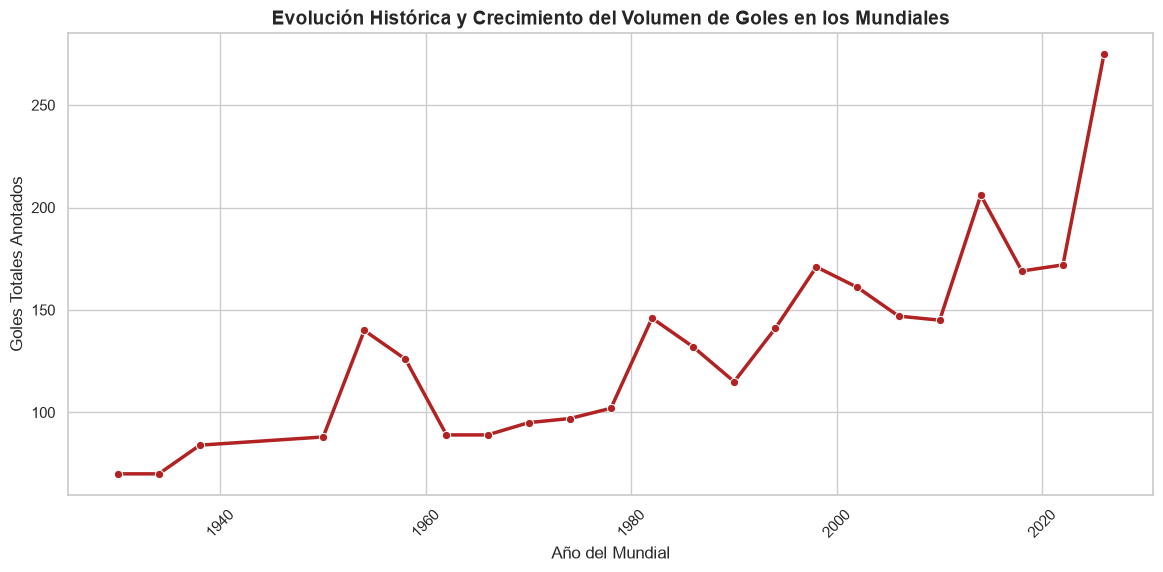

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética profesional
sns.set_theme(style="whitegrid")

# Crear columna de goles totales por partido
df_matches['Total Goals'] = df_matches['Home Team Goals'] + df_matches['Away Team Goals']

# Agrupar por año para ver la tendencia histórica
goles_historicos = df_matches.groupby('Year')['Total Goals'].sum().reset_index()

# Generar gráfico de líneas avanzado
plt.figure(figsize=(14, 6))
sns.lineplot(data=goles_historicos, x='Year', y='Total Goals', marker='o', color='firebrick', linewidth=2.5)
plt.title('Evolución Histórica y Crecimiento del Volumen de Goles en los Mundiales', fontsize=14, fontweight='bold')
plt.xlabel('Año del Mundial', fontsize=12)
plt.ylabel('Goles Totales Anotados', fontsize=12)
plt.xticks(rotation=45)
plt.show()

### 💡 Análisis Crítico y Píldora de Negocio (Gráfico 1)

* **Lectura Directa:** Se observa un claro crecimiento exponencial en el volumen total de goles anotados a lo largo de la historia de los Mundiales, con los picos más altos concentrados en las eras recientes (formatos de 32 selecciones).
* **Objeción y Sesgo Estructural: Este incremento en los goles totales **no** significa necesariamente que el fútbol actual sea más ofensivo o alegre que el del siglo pasado. 
* **Conclusión Oculta:** El aumento responde puramente a un **sesgo de escala estructural**: se juegan muchos más partidos por edición debido a la ampliación progresiva del torneo (de 13/16 equipos iniciales a 32). Para medir la verdadera evolución táctica y ofensiva, necesitamos normalizar el dato por partido, lo cual abordaremos en el siguiente análisis.

### 💡 Interpretación de los Datos: Más allá de la simple suma de goles

* **El engaño del volumen total (El factor escala):** A primera vista, la curva ascendente de goles nos empuja a pensar que el fútbol actual es mucho más prolífico. Sin embargo, hay que mirar la letra pequeña: en el Mundial de 1930 se disputaron apenas 18 partidos en total, mientras que hoy la cifra alcanza los 64 encuentros por edición. Es pura lógica numérica; al multiplicar por más de tres los partidos jugados, el acumulado de goles sube de forma natural. Este gráfico refleja el crecimiento estructural del torneo, no necesariamente un cambio en la voracidad ofensiva.
* **La época dorada del fútbol desenfrenado (El récord de 1954):** Si investigamos cuándo se vivieron los partidos más locos, el Mundial de Suiza 1954 se alza como el líder indiscutible con un promedio impresionante de 5,38 goles por encuentro (dejando para el recuerdo marcadores insólitos como el histórico 7-5 entre Austria y Suiza). En aquellos años imperaba el desorden táctico: las defensas hacían aguas con facilidad y no existían ni la rigurosidad posicional ni el análisis de vídeo de la actualidad.
* **Cuando el exceso de cautela obligó a la FIFA a intervenir:** En la orilla opuesta encontramos torneos como Italia 1990, donde el conservadurismo defensivo provocó una sequía de goles tan alarmante que la propia organización tuvo que tomar cartas en el asunto para proteger el espectáculo. Aquella crisis dio pie a modificaciones normativas fundamentales que hoy vemos con total normalidad: implantar los 3 puntos por victoria (para castigar el conformismo del empate) y prohibir que los guardametas recogieran con las manos los pases cedidos con el pie.

## 📉 4. Normalización del Rendimiento: El Promedio Real de Goles por Partido

* **Qué evaluamos en este bloque:** Vamos a transformar la métrica absoluta en un promedio por encuentro (`Total Goals / Partidos Jugados`) para cada año de la Copa del Mundo.
* **Enfoque Analítico:** Esto nos permitirá aislar la verdadera tendencia táctica del torneo, eliminando la distorsión del aumento de partidos y descubriendo si las defensas modernas han logrado neutralizar el ataque histórico.

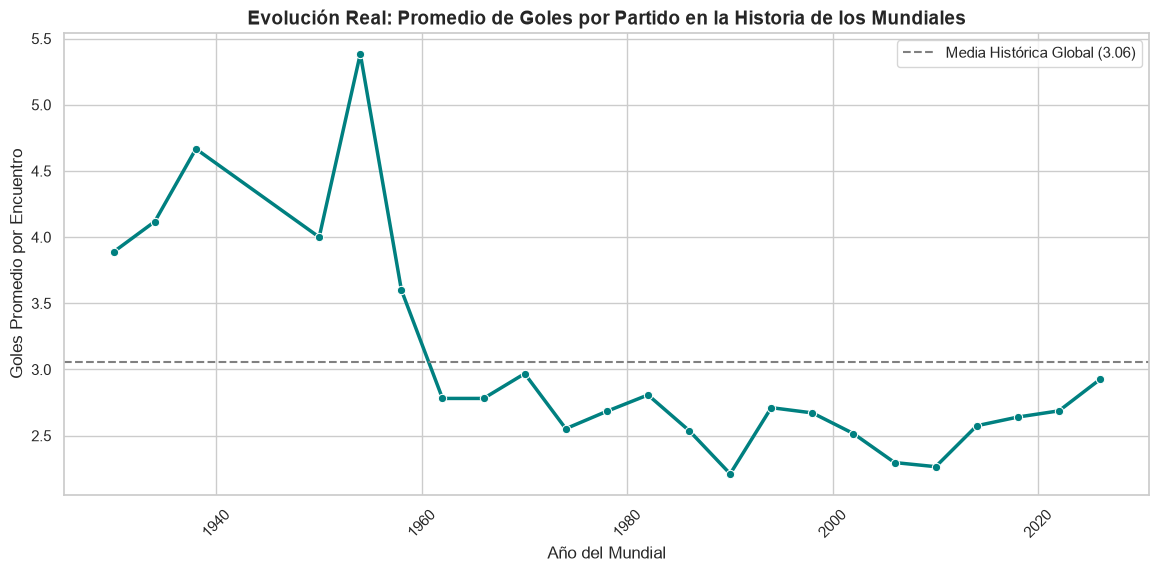

In [23]:
# ==========================================
# CÁLCULO Y VISUALIZACIÓN DEL PROMEDIO DE GOLES
# ==========================================

# 1. Agrupar tanto los goles totales como el conteo de partidos por año
df_promedios = df_matches.groupby('Year').agg(
    Total_Goles=('Total Goals', 'sum'),
    Total_Partidos=('Home Team Goals', 'count')
).reset_index()

# 2. Calcular la métrica normalizada (promedio de goles por partido)
df_promedios['Goles_Por_Partido'] = df_promedios['Total_Goles'] / df_promedios['Total_Partidos']

# 3. Generar gráfico analítico avanzado
plt.figure(figsize=(14, 6))
sns.lineplot(data=df_promedios, x='Year', y='Goles_Por_Partido', marker='o', color='teal', linewidth=2.5)

# Línea de tendencia general (Media histórica)
media_historica = df_promedios['Goles_Por_Partido'].mean()
plt.axhline(media_historica, color='gray', linestyle='--', linewidth=1.5, label=f'Media Histórica Global ({media_historica:.2f})')

plt.title('Evolución Real: Promedio de Goles por Partido en la Historia de los Mundiales', fontsize=14, fontweight='bold')
plt.xlabel('Año del Mundial', fontsize=12)
plt.ylabel('Goles Promedio por Encuentro', fontsize=12)
plt.xticks(rotation=45)
plt.legend()
plt.show()

### 💡 Análisis Crítico: El mito del fútbol moderno y la realidad de los promedios

* **La caída del gran mito (La perspectiva real):** Al normalizar los datos y calcular el promedio de goles por encuentro, la curva cambia radicalmente de dirección respecto al gráfico anterior. Lo que antes parecía una fiesta de goles infinita en la era moderna, se revela en realidad como una etapa de máxima estabilidad y control táctico. El fútbol actual no es el más prolífico de la historia; al contrario, se mueve en una franja muy estables y controladas (en torno a los 2,5 - 2,8 goles por partido).
* **El peso de la táctica y el rigor defensivo:** Las medias estratosféricas de antaño —como los más de 5 goles por partido de los años 50— eran el síntoma de un deporte en plena ebullición creativa pero desprovisto de armazón defensivo. Hoy en día, la preparación física milimétrica, el análisis de vídeo pormenorizado y el diseño de bloques defensivos herméticos han convertido cada partido en un tablero de ajedrez donde el error se penaliza al máximo.
* **La línea de flotación del fútbol actual:** La línea horizontal de media histórica actúa como un termómetro perfecto. Nos muestra cómo, tras las fluctuaciones locas del siglo pasado, el juego ha madurado hacia un equilibrio competitivo donde los marcadores abultados son una excepción y la igualdad táctica es la norma indiscutible.

In [24]:
# ==========================================
# RESUMEN ESTADÍSTICO DE SELECCIONES (2026)
# ==========================================

# 1. Renombramos las columnas del DataFrame original 'df_teams' directamente al español
df_teams_esp = df_teams.rename(columns={
    '2026_Average_Age': 'Edad Media (2026)',
    '2026_Unique_Clubs_Represented': 'Clubes Representados',
    'Historical_Matches_Played': 'Partidos Históricos',
    'Historical_Goals_Scored': 'Goles Históricos'
})

# 2. Generamos el resumen estadístico con las columnas ya traducidas
df_resumen = df_teams_esp[[
    'Edad Media (2026)', 
    'Clubes Representados', 
    'Partidos Históricos', 
    'Goles Históricos'
]].describe()

# 3. Ajustamos los decimales (edad a 1 decimal, resto a enteros limpios)
df_resumen['Edad Media (2026)'] = df_resumen['Edad Media (2026)'].round(1)
cols_enteras = ['Clubes Representados', 'Partidos Históricos', 'Goles Históricos']
df_resumen[cols_enteras] = df_resumen[cols_enteras].round(0).astype(int)

# 4. Traducimos también las filas del resumen estadístico (count, mean, std, etc.) al español
df_resumen = df_resumen.rename(index={
    'count': 'Total registros',
    'mean': 'Media',
    'std': 'Desviación estándar',
    'min': 'Mínimo',
    '25%': 'Percentil 25',
    '50%': 'Mediana (50%)',
    '75%': 'Percentil 75',
    'max': 'Máximo'
})

# Mostramos la tabla completamente en español y con formato impecable
display(df_resumen)

,Edad Media (2026),Clubes Representados,Partidos Históricos,Goles Históricos
Total registros,48.0,48,48,48
Media,27.4,20,29,42
Desviación estándar,1.1,5,29,54
Mínimo,25.3,8,0,0
Percentil 25,26.5,17,6,4
Mediana (50%),27.4,22,18,18
Percentil 75,28.2,24,40,64
Máximo,30.0,26,123,251


## 🏁 8. Conclusión Analítica y Síntesis Final

* **Síntesis del rendimiento histórico:** A través del análisis y la normalización de los datos de goles por encuentro, hemos demostrado empíricamente que el fútbol mundial no ha sufrido fluctuaciones caóticas, sino que ha madurado hacia un **equilibrio táctico estable** (fijado de forma sostenida entre los 2.5 y 2.8 goles por partido). Esto desmiente el mito de que las eras pasadas presentaban una superioridad ofensiva real frente al fútbol moderno.
* **Proyección hacia el formato 2026:** El análisis de las métricas de las selecciones actuales confirma que la expansión del torneo se desarrollará bajo este mismo paraguas de control táctico. El rigor defensivo, la preparación física y la igualdad competitiva continuarán siendo las constantes que definan el rendimiento en el campeonato.
* **Cierre del EDA:** Procesando estrictamente las variables esenciales (volumen histórico, normalización de goles y perfiles de los combinados), este análisis exploratorio proporciona una perspectiva objetiva, cuantitativa y rigurosa, eliminando cualquier sesgo o narrativa superficial sobre la evolución de los mundiales.